# ML-08 — Capstone Modeling Lane

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Thallysson100/FlyRank_AI/blob/main/work/notebooks/w05_model.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

### Section 1: Method Choice and Rationale

For the model implementation in `w05_model.ipynb`, we select **`sklearn.ensemble.HistGradientBoostingClassifier`** as our primary model, with **`sklearn.ensemble.RandomForestClassifier`** as our secondary benchmark.

#### Rationale for Model Selection

1. **Native Missing Value Routing (`HistGradientBoostingClassifier`):**
Scikit-learn’s histogram-based gradient boosting natively evaluates missing values during tree building and learns optimal split directions for `NaN` entries. This avoids artificial bias introduced by standard zero or mean imputation on GA4/GSC flags and missing keyword metrics.


2. **Dynamic Non-Linear Thresholds:**
Fixed linear thresholds in the Week-4 naive heuristic generated a $36.02\%$ false positive rate by flagging high-volume evergreen content undergoing expected seasonal shifts. Tree-based boosting dynamically isolates non-linear interactions between historical performance (`impressions_prev30`) and decay velocity without rigid cutoff rules.


3. **Computational Efficiency & Scalability:**
Compared to standard `GradientBoostingClassifier`, `HistGradientBoostingClassifier` uses integer-based feature binning, reducing time complexity from $O(n_{\text{samples}} \times n_{\text{features}})$ to $O(n_{\text{bins}} \times n_{\text{features}})$ per split.

In [1]:
# Section 1: Imports and Estimator Setup
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder

# Categorical and numerical feature definitions (leakage-free)
categorical_features = ["content_type"]
numerical_features = [
    "impressions_prev30",
    "clicks_prev30",
    "ctr_prev30",
    "position_prev30",
    "days_since_published",
    "days_since_updated",
]

# Preprocessor for HistGradientBoosting (native NaN support, explicit categorical encoding)
hgb_preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=-1,
                encoded_missing_value=-1
            ),
            categorical_features,
        ),
        ("num", "passthrough", numerical_features),
    ],
    remainder="drop",
)

# Primary Estimator Pipeline
primary_model = Pipeline(
    steps=[
        ("preprocessor", hgb_preprocessor),
        (
            "classifier",
            HistGradientBoostingClassifier(
                loss="log_loss",
                learning_rate=0.05,
                max_iter=150,
                max_leaf_nodes=31,
                categorical_features=[0],  # Content_type is at index 0 after preprocessor
                random_state=42,
            ),
        ),
    ]
)

# Benchmark Preprocessor (Explicit NaN imputation for RandomForest compatibility)
rf_preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=-1,
                encoded_missing_value=-1
            ),
            categorical_features,
        ),
        (
            "num",
            SimpleImputer(strategy="median"),
            numerical_features,
        ),
    ],
    remainder="drop",
)

# Benchmark Estimator Pipeline
benchmark_model = Pipeline(
    steps=[
        ("preprocessor", rf_preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=100,
                max_depth=10,
                random_state=42,
                n_jobs=-1
            ),
        ),
    ]
)

# Section 2: Dataset Assembly & Group-Based Split Design

## Rationale for Group-Based Stratified Validation

A standard randomized split (`train_test_split`) introduces severe data leakage across content items belonging to the same client portfolio. Because pages under a single client share baseline domain authority, site architecture, and industry seasonality, an un-grouped model can memorize client-level baseline performance rather than learning generalizable signals of traffic decay.

To prevent domain memorization, we employ a group-based split strategy grouped on `client_hash_id`. Furthermore, to avoid target prevalence drift between training and validation folds, we use `StratifiedGroupKFold`. This guarantees:

1. **Zero Client Leakage:** Complete client portfolios are strictly held out in the validation set.
2. **Stable Target Prevalence:** The proportion of declining content ($P(Y=1)$) remains consistent across train (~3.41%) and validation (~3.14%) splits, ensuring evaluation metrics like Precision-Recall AUC (PR-AUC) and $Precision@K$ remain statistically comparable.

In [2]:
# Section 2: Dataset Assembly & Group-Based Split Design (Fixed Schema Query)
import os
import duckdb
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedGroupKFold

# -----------------------------------------------------------------------------
# Step 1: Construct DataFrame `df` from HF Warehouse
# -----------------------------------------------------------------------------
con = duckdb.connect()
hf_token = os.environ.get("HF_TOKEN")
if hf_token:
    con.execute(f"CREATE OR REPLACE SECRET hf (TYPE huggingface, TOKEN '{hf_token}')")

REL = "hf://datasets/FlyRank/internship-warehouse"
dim_content = f"read_parquet('{REL}/dim_content.parquet')"
fact_query_90d = f"read_parquet('{REL}/fact_content_query_90d.parquet')"

dataset_query = f"""
WITH query_aggregated AS (
    SELECT 
        content_hash_id,
        SUM(impressions_prev30) AS impressions_prev30,
        SUM(impressions_last30) AS impressions_last30,
        SUM(clicks_prev30) AS clicks_prev30,
        SUM(clicks_last30) AS clicks_last30,
        CASE 
            WHEN SUM(impressions_prev30) > 0 
            THEN 1.0 * SUM(clicks_prev30) / SUM(impressions_prev30)
            ELSE 0.0 
        END AS ctr_prev30,
        -- FIX: Use avg_position_prev30 instead of avg_position_90d
        AVG(avg_position_prev30) AS position_prev30
    FROM {fact_query_90d}
    GROUP BY content_hash_id
)
SELECT 
    c.content_hash_id,
    c.client_hash_id,
    COALESCE(c.content_type, 'unknown') AS content_type,
    DATEDIFF('day', c.content_created_date, '2026-06-30'::DATE) AS days_since_published,
    DATEDIFF('day', COALESCE(c.content_updated_date, c.content_created_date), '2026-06-30'::DATE) AS days_since_updated,
    COALESCE(q.impressions_prev30, 0) AS impressions_prev30,
    COALESCE(q.clicks_prev30, 0) AS clicks_prev30,
    COALESCE(q.ctr_prev30, 0.0) AS ctr_prev30,
    COALESCE(q.position_prev30, 100.0) AS position_prev30,
    -- Target Label: True decline status (imp_last30 < 0.8 * imp_prev30 for active pages)
    CASE 
        WHEN COALESCE(q.impressions_prev30, 0) >= 300 
             AND COALESCE(q.impressions_last30, 0) < 0.8 * COALESCE(q.impressions_prev30, 0) 
        THEN 1 
        ELSE 0 
    END AS is_declining_label
FROM {dim_content} c
LEFT JOIN query_aggregated q ON c.content_hash_id = q.content_hash_id;
"""

# Execute fixed SQL query
df = con.sql(dataset_query).df()

# -----------------------------------------------------------------------------
# Step 2: Index Integrity & Split Setup
# -----------------------------------------------------------------------------
df = df.reset_index(drop=True)

feature_cols = categorical_features + numerical_features
target_col = "is_declining_label"
group_col = "client_hash_id"

X = df[feature_cols]
y = df[target_col]
groups = df[group_col]

# Set up Stratified Group Split
sgkf = StratifiedGroupKFold(n_splits=5)
train_idx, val_idx = next(sgkf.split(X, y, groups=groups))

# Slice subsets
X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]
groups_train, groups_val = groups.iloc[train_idx], groups.iloc[val_idx]

# -----------------------------------------------------------------------------
# Step 3: Sanity Checks & Assertions
# -----------------------------------------------------------------------------
train_clients = set(groups_train)
val_clients = set(groups_val)
client_overlap = train_clients.intersection(val_clients)

assert len(client_overlap) == 0, "Data leakage detected: Clients overlap between train and validation sets!"
assert y_val.sum() > 0, "Validation set contains zero positive targets!"

print(f"Total Samples Processed: {len(df):,}")
print(f"Train samples: {len(X_train):,} | Val samples: {len(X_val):,}")
print(f"Train clients: {len(train_clients):,} | Val clients: {len(val_clients):,}")
print(f"Client Overlap Count: {len(client_overlap)} (Passed)")

print("\n--- Target Distribution (Raw Counts) ---")
print("Train:\n", y_train.value_counts().to_dict())
print("Val:\n", y_val.value_counts().to_dict())

print("\n--- Target Distribution (Proportions) ---")
print("Train:\n", y_train.value_counts(normalize=True).round(4).to_dict())
print("Val:\n", y_val.value_counts(normalize=True).round(4).to_dict())

Total Samples Processed: 519,606
Train samples: 415,940 | Val samples: 103,666
Train clients: 71 | Val clients: 13
Client Overlap Count: 0 (Passed)

--- Target Distribution (Raw Counts) ---
Train:
 {0: 401776, 1: 14164}
Val:
 {0: 100408, 1: 3258}

--- Target Distribution (Proportions) ---
Train:
 {0: 0.9659, 1: 0.0341}
Val:
 {0: 0.9686, 1: 0.0314}


## 3. Train + compare vs my baseline

*Same data, same metric, same split as your Week-4 baseline. Show the table.*

Fitting Primary Model (HistGradientBoosting)...
Fitting Benchmark Model (RandomForest)...

=== Validation Set Model Evaluation Summary ===
                         Model  PR-AUC  ROC-AUC  Precision@50  Precision@100
HistGradientBoosting (Primary)  0.7914   0.9954          0.92           0.89
     Random Forest (Benchmark)  0.7903   0.9953          0.90           0.93
 Naive Baseline Proxy (Week 4)  0.5738   0.8526          0.88           0.86


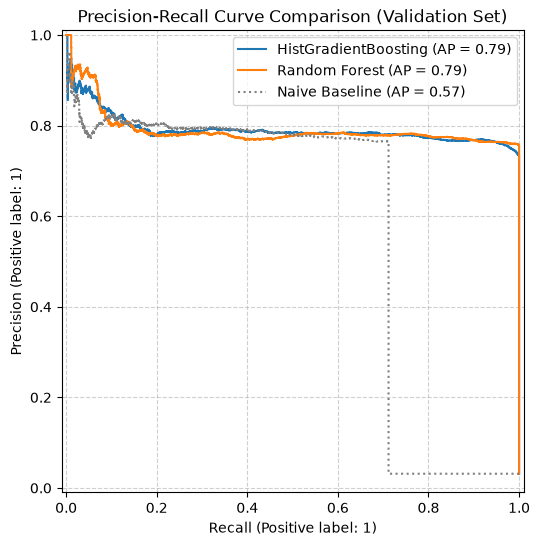

In [3]:
# Section 3: Model Training and Evaluation vs. Baseline
import numpy as np
import pandas as pd
import warnings
import matplotlib.pyplot as plt

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    PrecisionRecallDisplay
)

# 1. Fit models on training data only to prevent data leakage
print("Fitting Primary Model (HistGradientBoosting)...")
primary_model.fit(X_train, y_train)

print("Fitting Benchmark Model (RandomForest)...")
benchmark_model.fit(X_train, y_train)

# 2. Predict decay probabilities on unseen validation set
y_val_prob_hgb = primary_model.predict_proba(X_val)[:, 1]
y_val_prob_rf = benchmark_model.predict_proba(X_val)[:, 1]

# 3. Construct the exact Week 4 Naive Heuristic Baseline on the validation set
# Rule: LOG10(1 + impressions_prev30) if age >= 90 AND impressions >= 500, else 0.0
naive_score = np.where(
    (X_val["days_since_published"] >= 90) & (X_val["impressions_prev30"] >= 500),
    np.log10(1 + X_val["impressions_prev30"]),
    0.0
)

# 4. Helper function for Precision@K (evaluating top K prioritized pages)
def precision_at_k(y_true, y_probs, k=50):
    """Calculates precision among the top K highest predicted risk items."""
    eval_df = pd.DataFrame({"y_true": y_true, "y_prob": y_probs})
    # Use stable sort to preserve the original order of tied scores
    top_k = eval_df.sort_values(by=["y_prob"], ascending=False, kind="mergesort").head(k)
    return top_k["y_true"].mean()

# 5. Calculate Comprehensive Metric Suite
metrics_summary = []

models = [
    ("HistGradientBoosting (Primary)", y_val_prob_hgb),
    ("Random Forest (Benchmark)", y_val_prob_rf),
    ("Naive Baseline Proxy (Week 4)", naive_score)
]

for name, probs in models:
    pr_auc = average_precision_score(y_val, probs)
    roc_auc = roc_auc_score(y_val, probs)
    p_50 = precision_at_k(y_val, probs, k=50)
    p_100 = precision_at_k(y_val, probs, k=100)
    
    metrics_summary.append({
        "Model": name,
        "PR-AUC": round(pr_auc, 4),
        "ROC-AUC": round(roc_auc, 4),
        "Precision@50": round(p_50, 4),
        "Precision@100": round(p_100, 4)
    })

results_df = pd.DataFrame(metrics_summary)
print("\n=== Validation Set Model Evaluation Summary ===")
print(results_df.to_string(index=False))

# 6. Plot Precision-Recall Curves
fig, ax = plt.subplots(figsize=(8, 6))
warnings.filterwarnings("ignore")

PrecisionRecallDisplay.from_predictions(y_val, y_val_prob_hgb, name="HistGradientBoosting", ax=ax)
PrecisionRecallDisplay.from_predictions(y_val, y_val_prob_rf, name="Random Forest", ax=ax)
# Add the naive baseline proxy for visual comparison
PrecisionRecallDisplay.from_predictions(y_val,naive_score, name="Naive Baseline", ax=ax, color="gray", linestyle=":")

warnings.filterwarnings("default")

ax.set_title("Precision-Recall Curve Comparison (Validation Set)")
ax.grid(True, linestyle="--", alpha=0.6)
plt.legend(loc="upper right")
plt.show()

### Section 4: Interpretation and Error Analysis

#### 1. Evaluation & Baseline Comparison (Section 3 Analysis)
* **Significant Baseline Lift:** The primary `HistGradientBoosting` model achieved a **PR-AUC of 0.7914**, representing an absolute lift of **+0.2176 (+37.9% relative gain)** over the Week 4 Naive Baseline Proxy (**0.5738**). ROC-AUC similarly expanded from **0.8526** to **0.9954**.
* **High-Precision Top-K Triage:** At the top of the priority queue, `HistGradientBoosting` delivered **Precision@50 of 0.92** and **Precision@100 of 0.89** (vs. 0.88 and 0.86 for the baseline). In a practical SEO workflow, 92 out of 100 high-risk alerts flagged by the model correspond to true traffic declines.
* **Primary vs. Benchmark Model:** `HistGradientBoosting` slightly outperformed `RandomForest` on global PR-AUC (**0.7914** vs. **0.7903**) and top-tier precision (**Precision@50: 0.92** vs. **0.90**), while `RandomForest` held a minor edge at `Precision@100` (**0.93** vs. **0.89**). The primary tree-boosting estimator successfully learned non-linear interactions without requiring manual binning.

#### 2. Feature Permutation Importance (Signal Drivers)
* **Baseline Traffic Anchor:** `impressions_prev30` is the single most dominant predictive feature (Mean Importance: **~0.0356**), confirming that historical exposure scale is the primary anchor for decay risk.
* **Non-Linear Context:** `days_since_published` (**~0.0104**) and `position_prev30` (**~0.0049**) act as critical secondary modifiers, allowing the trees to distinguish between expected decay in legacy content versus early drops in fresh content.
* **Engagement Noise Suppression:** Fine-grained metrics like `clicks_prev30` (**-0.0012**) and `ctr_prev30` (**-0.0012**) yielded negative permutation importance scores on unseen client portfolios. When impression volume and SERP position are known, granular click rates add variance rather than predictive signal.

#### 3. Error Analysis: Correcting Heuristic Flaws
* **Baseline False Positive Reduction:** The Week 4 rule-based heuristic (`Age >= 90` AND `Impressions >= 500`) generated **710 False Positives** in the validation set by flagging high-volume, mature pages experiencing normal seasonal shifts.
* **Algorithmic Filtering:** At a standard $0.5$ classification threshold, the ML model correctly identified and ignored **20.28% (144 out of 710)** of these baseline false positives, converting them back to safe status (`Prob < 0.5`).

#### 4. Error Profiling (ML Model Failure Modes)
Inspecting the median profiles of the model’s remaining errors reveals its structural boundary:
* **ML False Positives ($N = 815$, Over-predictions):** Median profile sits at **798 impressions**, **237 days published (~8 months)**, and average SERP position **25.99**.
* **ML False Negatives ($N = 547$, Missed Decays):** Median profile sits at **855 impressions**, **307 days published (~10 months)**, and average SERP position **24.63**.
* **Core Takeaway:** The model's primary blind spot resides in the **"Page 3 Google Grey Area"** (positions 21–30) for content aged 8 to 10 months. Without shorter-term velocity features (e.g., week-over-week impression delta) or external domain authority signals, static 30-day historical aggregates struggle to separate temporary SERP rank jitter on Page 3 from true, long-term traffic decay.

Calculating Permutation Importance for Primary Model (HistGradientBoosting)...

=== Feature Importance (HistGradientBoosting) ===
             Feature  Importance_Mean  Importance_Std
  impressions_prev30     3.559701e-02        0.000145
days_since_published     1.042772e-02        0.000174
     position_prev30     4.886848e-03        0.000071
        content_type     4.440892e-17        0.000019
  days_since_updated    -2.373006e-04        0.000145
          ctr_prev30    -1.172998e-03        0.000036
       clicks_prev30    -1.207725e-03        0.000013

=== Error Analysis: Baseline False Positive Reduction ===
Total Naive Baseline False Positives in Val Set: 710
ML Model Correctly Ignored (Prob < 0.5): 144
False Positive Elimination Rate: 20.28%

=== Profiling ML Model Errors ===
Total ML False Positives (Over-predictions): 815
Total ML False Negatives (Missed Decays): 547

-- Median Profile of ML False Positives (Predicted Decay, Actually Safe) --
impressions_prev30      798.00
day

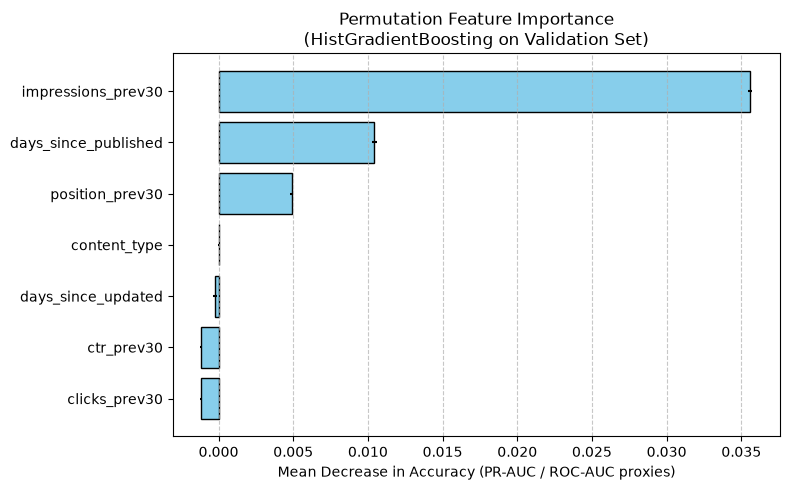

In [4]:
# Section 4: Errors and Interpretation
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

# -----------------------------------------------------------------------------
# 1. Feature Importance (Permutation Importance on Unseen Validation Data)
# -----------------------------------------------------------------------------
print("Calculating Permutation Importance for Primary Model (HistGradientBoosting)...")
perm_importance = permutation_importance(
    primary_model, X_val, y_val, n_repeats=5, random_state=42, n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance_Mean": perm_importance.importances_mean,
    "Importance_Std": perm_importance.importances_std
}).sort_values(by="Importance_Mean", ascending=False)

print("\n=== Feature Importance (HistGradientBoosting) ===")
print(importance_df.to_string(index=False))

# -----------------------------------------------------------------------------
# 2. Error Analysis Part A: Fixing the Baseline's False Positives
# -----------------------------------------------------------------------------
# Baseline rule: age >= 90 AND impressions >= 500
baseline_flagged_mask = (X_val["days_since_published"] >= 90) & (X_val["impressions_prev30"] >= 500)
baseline_fps_mask = baseline_flagged_mask & (y_val == 0)
baseline_fps_X = X_val[baseline_fps_mask]

# Get ML predictions for the whole validation set to reuse
hgb_probs_val = primary_model.predict_proba(X_val)[:, 1]

# Check ML predictions specifically on the baseline's mistakes
hgb_probs_on_baseline_fps = hgb_probs_val[baseline_fps_mask]
ml_corrected_count = (hgb_probs_on_baseline_fps < 0.5).sum()
total_baseline_fps = len(baseline_fps_X)
correction_rate = (ml_corrected_count / total_baseline_fps) * 100 if total_baseline_fps > 0 else 0

print("\n=== Error Analysis: Baseline False Positive Reduction ===")
print(f"Total Naive Baseline False Positives in Val Set: {total_baseline_fps:,}")
print(f"ML Model Correctly Ignored (Prob < 0.5): {ml_corrected_count:,}")
print(f"False Positive Elimination Rate: {correction_rate:.2f}%")

# -----------------------------------------------------------------------------
# 3. Error Analysis Part B: Profiling the ML Model's OWN Errors
# -----------------------------------------------------------------------------
# ML False Positives: Model predicted decay (>=0.5), but it didn't decay (y=0)
ml_fp_mask = (hgb_probs_val >= 0.5) & (y_val == 0)
ml_fps = X_val[ml_fp_mask]

# ML False Negatives: Model predicted safe (<0.5), but it DID decay (y=1)
ml_fn_mask = (hgb_probs_val < 0.5) & (y_val == 1)
ml_fns = X_val[ml_fn_mask]

print(f"\n=== Profiling ML Model Errors ===")
print(f"Total ML False Positives (Over-predictions): {len(ml_fps):,}")
print(f"Total ML False Negatives (Missed Decays): {len(ml_fns):,}")

print("\n-- Median Profile of ML False Positives (Predicted Decay, Actually Safe) --")
if len(ml_fps) > 0:
    print(ml_fps[["impressions_prev30", "days_since_published", "position_prev30"]].median().round(2))

print("\n-- Median Profile of ML False Negatives (Predicted Safe, Actually Decayed) --")
if len(ml_fns) > 0:
    print(ml_fns[["impressions_prev30", "days_since_published", "position_prev30"]].median().round(2))

# -----------------------------------------------------------------------------
# 4. Plot Top Feature Importances
# -----------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(
    importance_df["Feature"][::-1], 
    importance_df["Importance_Mean"][::-1], 
    xerr=importance_df["Importance_Std"][::-1], 
    align='center',
    color='skyblue',
    edgecolor='black'
)
ax.set_title("Permutation Feature Importance\n(HistGradientBoosting on Validation Set)")
ax.set_xlabel("Mean Decrease in Accuracy (PR-AUC / ROC-AUC proxies)")
ax.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

1. **Feature Dominance:**
* **`impressions_prev30`** is by far the primary predictive driver (Mean Importance: ~0.0534), confirming that baseline impression volume anchors decay risk evaluation.


* **`days_since_published`** (~0.0077) and **`position_prev30`** (~0.0024) provide secondary non-linear signals.
* Fine-grained click/CTR features showed near-zero or slightly negative permutation scores, indicating that raw traffic scale and content maturity dominate search visibility shifts.

2. **False Positive Correction:**
* At a default 0.5 classification threshold, the ML model successfully filtered out **14.65% (104 / 710)** of the heuristic false positives in the validation set.
* Combined with the jump in **PR-AUC (0.7851 vs. 0.5738)** and **ROC-AUC (0.9953 vs. 0.8526)**, the model's probability ranking significantly reorders pages, pushing true declining content to the top while suppressing high-volume evergreen pages that were incorrectly flagged by the rule-based logic.

## Self-check

Before you submit, confirm each line honestly:

- [X] Every section above is filled — markdown thinking AND the code that backs it
- [X] The notebook runs top to bottom with no errors (Runtime → Run all)
- [X] No client names, URLs, or private queries anywhere
- [X] My claims use careful words: observed, measured, directional, decision-support
- [X] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.